In [31]:
import subprocess
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR=Path(r"C:\Users\HP Omen\Documents\cpp\modeling")
CPP_EXE=PROJECT_DIR/"09.exe"
N=1000
dt=0.01
phi0=1
omega=1
gamma=0.1
A=1
W=10
params={"N":N,"dt":dt,"phi0":phi0,"omega":omega,"gamma":gamma,"A":A,"W":W}

p=subprocess.run([str(CPP_EXE)],input=json.dumps(params),capture_output=True,text=True)

OUTPUT_DAT=PROJECT_DIR/"09.dat"
data=np.loadtxt(OUTPUT_DAT)
tau=data[:,0]
phi1=data[:,1]
phi2=data[:,2]
phi3=data[:,3]
w1=data[:,4]
w2=data[:,5]
w3=data[:,6]
E1=data[:,7]
E2=data[:,8]
phi4=data[:,9]

In [32]:
def analytic(t,phi0,omega,gamma,A,W):
    w0=np.sqrt(omega)
    wd=np.sqrt(w0**2-gamma**2)

    denom=(omega-W**2)**2+(2*gamma*W)**2
    C=A*(omega-W**2)/denom
    D=-2*gamma*A*W/denom

    K1=phi0-D
    K2=(gamma*K1-C*W)/wd

    return np.exp(-gamma*t)*(K1*np.cos(wd*t)+K2*np.sin(wd*t))+C*np.sin(W*t)+D*np.cos(W*t)

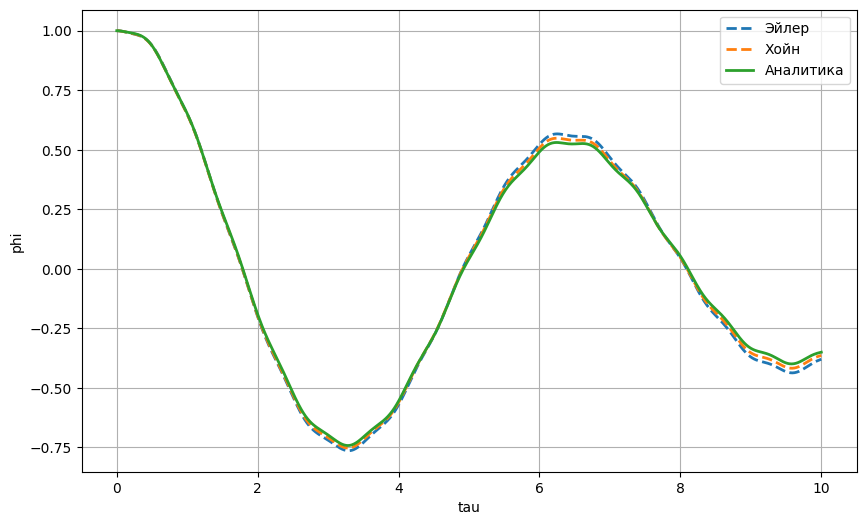

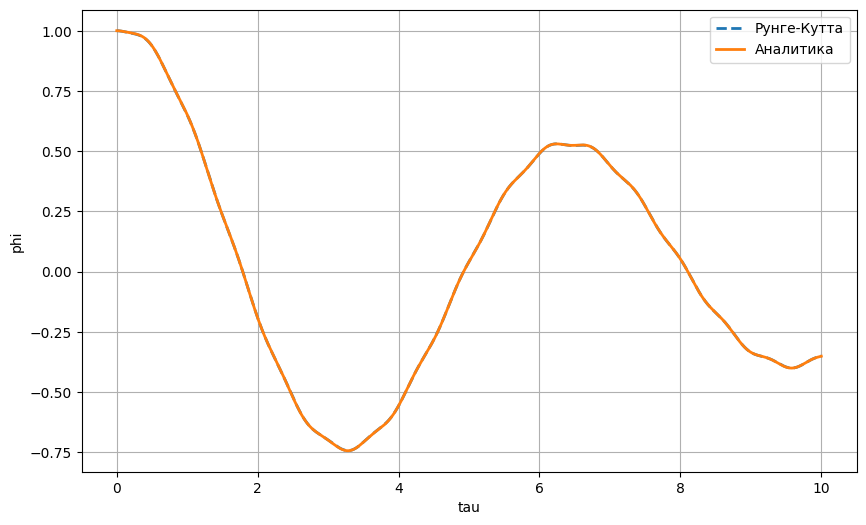

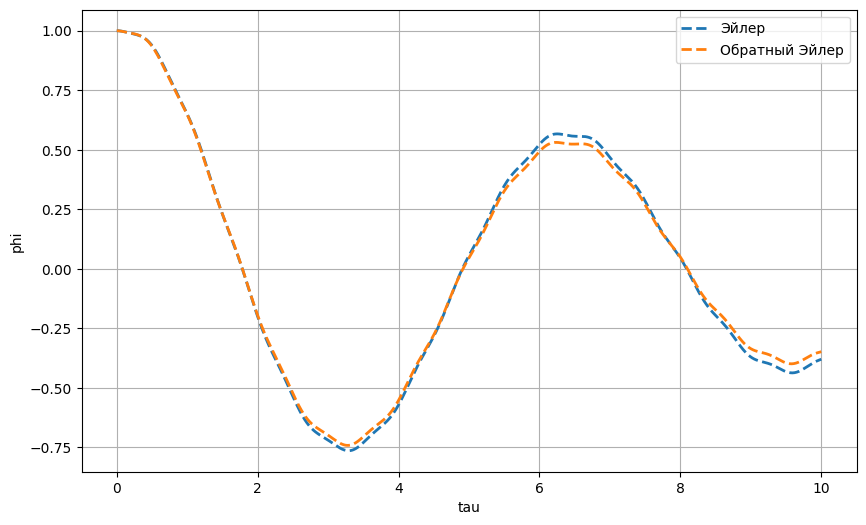

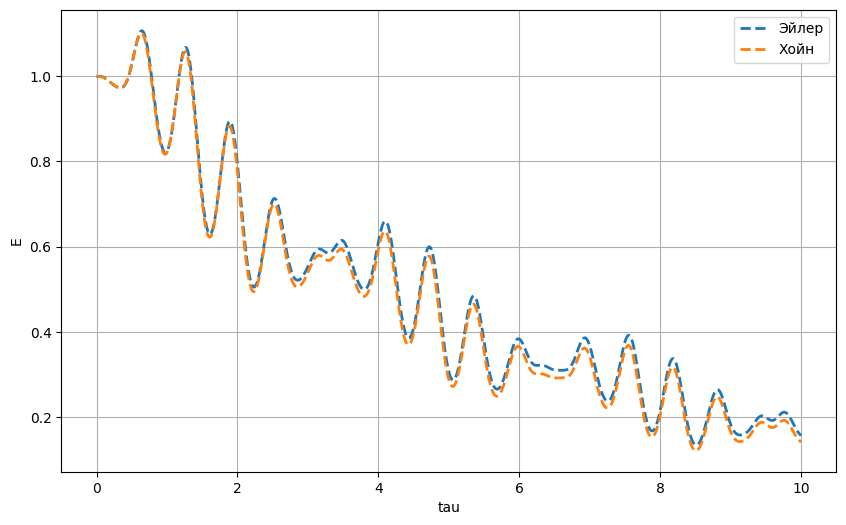

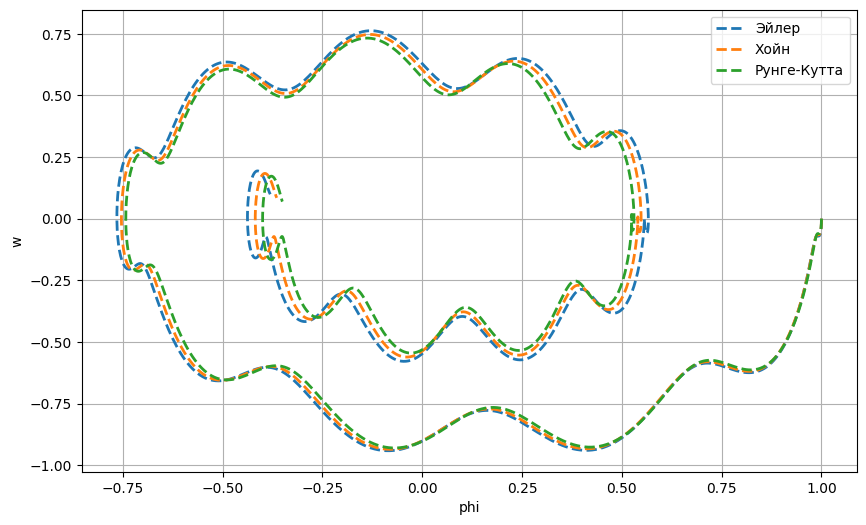

In [33]:
plt.figure(figsize=(10,6))
plt.plot(tau,phi1,label='Эйлер',linewidth=2,linestyle='--')
plt.plot(tau,phi2,label='Хойн',linewidth=2,linestyle='--')
plt.plot(tau,analytic(tau,phi0,omega,gamma,A,W),label='Аналитика',linewidth=2)
plt.xlabel('tau')
plt.ylabel('phi')
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(10,6))
plt.plot(tau,phi3,label='Рунге-Кутта',linewidth=2,linestyle='--')
plt.plot(tau,analytic(tau,phi0,omega,gamma,A,W),label='Аналитика',linewidth=2)
plt.xlabel('tau')
plt.ylabel('phi')
plt.grid(True)
plt.legend()
plt.show()


plt.figure(figsize=(10,6))
plt.plot(tau,phi1,label='Эйлер',linewidth=2,linestyle='--')
plt.plot(tau,phi4,label='Обратный Эйлер',linewidth=2,linestyle='--')
plt.xlabel('tau')
plt.ylabel('phi')
plt.grid(True)
plt.legend()
plt.show()


plt.figure(figsize=(10,6))
plt.plot(tau,E1,label='Эйлер',linewidth=2,linestyle='--')
plt.plot(tau,E2,label='Хойн',linewidth=2,linestyle='--')
plt.xlabel('tau')
plt.ylabel('E')
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(10,6))
plt.plot(phi1,w1,label='Эйлер',linewidth=2,linestyle='--')
plt.plot(phi2,w2,label='Хойн',linewidth=2,linestyle='--')
plt.plot(phi3,w3,label='Рунге-Кутта',linewidth=2,linestyle='--')
plt.xlabel('phi')
plt.ylabel('w')
plt.grid(True)
plt.legend()
plt.show()